In [16]:
import numpy as np
import pandas as pd

In [17]:
# Generate data
rng = np.random.default_rng(42)

players = [
    "Player A", "Player B", "Player C", "Player D",
    "Player E", "Player F", "Player G", "Player H",
    "Player I", "Player J", "Player K", "Player L"
]

# Fictional player profiles. These probabilities are illustrative.
profiles = {
    "Player A": [0.40, 0.25, 0.20, 0.15],
    "Player B": [0.20, 0.20, 0.25, 0.35],
    "Player C": [0.30, 0.25, 0.20, 0.25],
    "Player D": [0.15, 0.25, 0.25, 0.35],
    "Player E": [0.35, 0.20, 0.25, 0.20],
    "Player F": [0.20, 0.30, 0.20, 0.30],
    "Player G": [0.25, 0.25, 0.25, 0.25],
    "Player H": [0.30, 0.15, 0.20, 0.35],
    "Player I": [0.20, 0.25, 0.30, 0.25],
    "Player J": [0.35, 0.25, 0.15, 0.25],
    "Player K": [0.25, 0.20, 0.20, 0.35],
    "Player L": [0.15, 0.20, 0.25, 0.40],
}

shot_types = ["layup", "mid_range", "corner_three", "above_break_three"]

# Positive values mean better shooting in the simulation.
player_effects = dict(zip(
    players,
    rng.normal(loc=0, scale=0.18, size=len(players))
))

rows = []

for player in players:
    n_shots = 1_500

    shot_type = rng.choice(
        shot_types,
        size=n_shots,
        p=profiles[player]
    )

    distance = np.select(
        [
            shot_type == "layup",
            shot_type == "mid_range",
            shot_type == "corner_three",
            shot_type == "above_break_three"
        ],
        [
            rng.normal(3, 1.2, n_shots),
            rng.normal(15, 4, n_shots),
            rng.normal(23, 0.5, n_shots),
            rng.normal(26, 2, n_shots)
        ]
    )

    distance = np.clip(distance, 1, 35)

    is_three = np.isin(
        shot_type,
        ["corner_three", "above_break_three"]
    ).astype(int)

    is_corner_three = (
        shot_type == "corner_three"
    ).astype(int)

    late_clock = rng.binomial(1, 0.18, n_shots)

    # The following formula generates the synthetic outcomes.
    # It is not a fitted NBA model.
    logit = (
        1.25
        - 0.075 * distance
        - 0.30 * is_three
        - 0.45 * (shot_type == "mid_range")
        + 0.30 * is_corner_three
        - 0.45 * late_clock
        + player_effects[player]
    )

    probability = 1 / (1 + np.exp(-logit))
    made = rng.binomial(1, probability)

    rows.append(pd.DataFrame({
        "player": player,
        "shot_type": shot_type,
        "distance": distance,
        "is_three": is_three,
        "is_corner_three": is_corner_three,
        "late_clock": late_clock,
        "made": made
    }))

shots = pd.concat(rows, ignore_index=True)

shots["points"] = (
    shots["made"] * np.where(shots["is_three"] == 1, 3, 2)
)
display(shots.sample(5))
print(f"Total shots: {len(shots):,}")


,player,shot_type,distance,is_three,is_corner_three,late_clock,made,points
3282,Player C,mid_range,18.291396,0,0,0,0,0
12652,Player I,mid_range,19.108736,0,0,0,1,2
2392,Player B,above_break_three,25.592072,1,0,1,1,3
12374,Player I,layup,1.849927,0,0,0,1,2
14983,Player J,mid_range,13.584851,0,0,0,1,2


Total shots: 18,000


In [18]:
# Logistic regression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss

numeric_features = ["distance", "is_three", "is_corner_three", "late_clock"]
categorical_features = ["shot_type"]
features = numeric_features + categorical_features

X = shots[features]
y = shots["made"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_features
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1_000))
])

model.fit(X_train, y_train)

test_predictions = model.predict_proba(X_test)[:, 1]

print("Log loss:", round(log_loss(y_test, test_predictions), 4))
print("ROC AUC:", round(roc_auc_score(y_test, test_predictions), 4))
print("Brier score:", round(brier_score_loss(y_test, test_predictions), 4))


Log loss: 0.6195
ROC AUC: 0.6999
Brier score: 0.2146


In [19]:
# xpps
shots["xfg"] = model.predict_proba(shots[features])[:, 1]

shots["shot_value"] = np.where(shots["is_three"] == 1, 3, 2)

shots["expected_points"] = (shots["xfg"] * shots["shot_value"])

shots["points_above_expected"] = (shots["points"] - shots["expected_points"])


In [20]:
# Separating shot selection from shot making
player_summary = (
    shots.groupby("player")
    .agg(
        attempts=("made", "size"),
        fg_pct=("made", "mean"),
        xfg_pct=("xfg", "mean"),
        xpps=("expected_points", "mean"),
        actual_pps=("points", "mean"),
        points_above_expected=(
            "points_above_expected", "sum"
        )
    )
    .reset_index()
)

player_summary["fg_pct"] *= 100
player_summary["xfg_pct"] *= 100

player_summary["points_above_expected_per_100"] = (
    100 * player_summary["points_above_expected"] / player_summary["attempts"]
)

player_summary = player_summary.sort_values("points_above_expected_per_100", ascending=False)

player_summary.round(2)


,player,attempts,fg_pct,xfg_pct,xpps,actual_pps,points_above_expected,points_above_expected_per_100
3,Player D,1500,43.53,38.78,0.96,1.09,190.54,12.70
0,Player A,1500,52.53,48.99,1.09,1.17,119.90,7.99
11,Player L,1500,41.40,38.64,0.96,1.03,99.32,6.62
2,Player C,1500,46.93,44.21,1.02,1.08,88.06,5.87
7,Player H,1500,45.20,43.85,1.04,1.08,56.98,3.80
10,Player K,1500,43.87,42.28,1.01,1.05,55.57,3.70
8,Player I,1500,41.73,41.31,1.01,1.02,27.01,1.80
6,Player G,1500,41.27,42.42,1.01,0.98,-36.60,-2.44
1,Player B,1500,39.40,40.34,0.99,0.96,-37.01,-2.47
9,Player J,1500,44.20,46.13,1.04,0.99,-82.02,-5.47


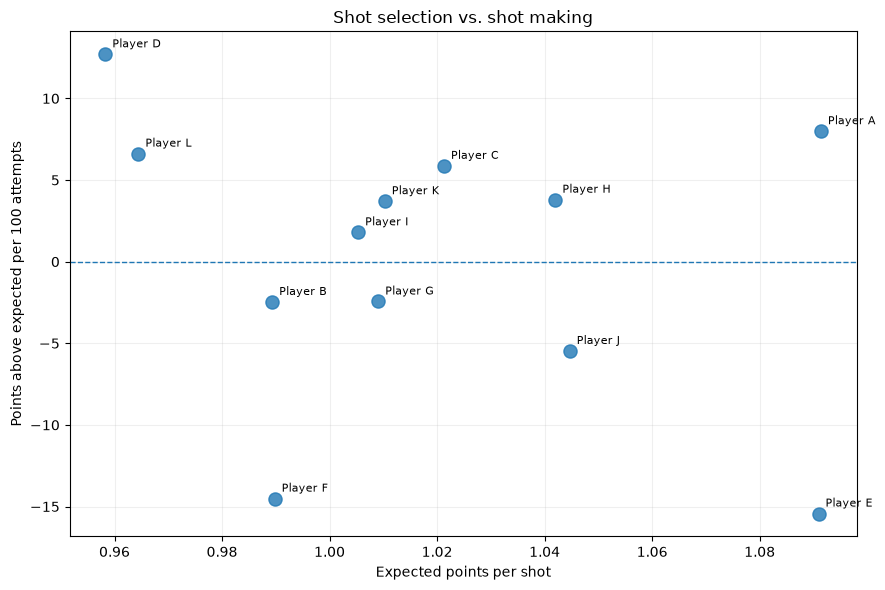

In [21]:
# chart 1
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

scatter = ax.scatter(
    player_summary["xpps"],
    player_summary["points_above_expected_per_100"],
    s=90,
    alpha=0.8
)

for _, row in player_summary.iterrows():
    ax.annotate(
        row["player"],
        (
            row["xpps"],
            row["points_above_expected_per_100"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Expected points per shot")
ax.set_ylabel("Points above expected per 100 attempts")
ax.set_title("Shot selection vs. shot making")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


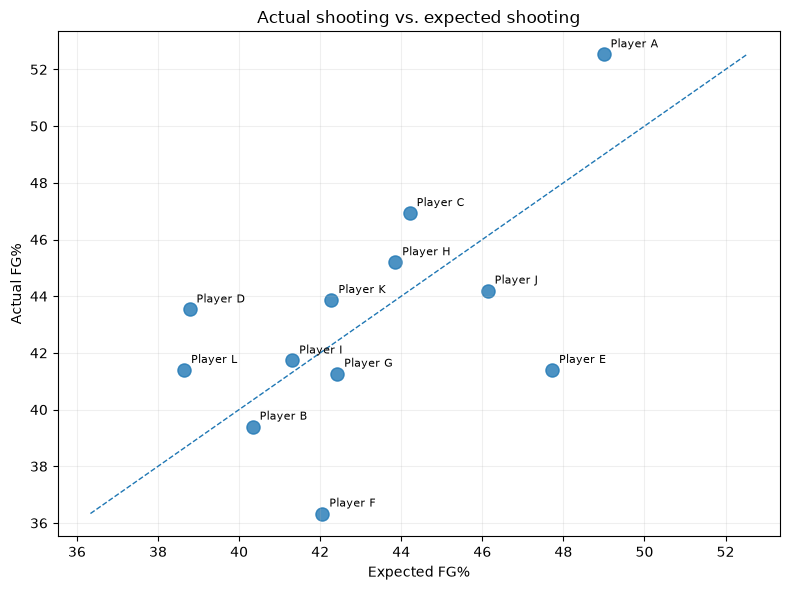

In [22]:
# FG% vs xFG%
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    player_summary["xfg_pct"],
    player_summary["fg_pct"],
    s=90,
    alpha=0.8
)

lower = min(
    player_summary["xfg_pct"].min(),
    player_summary["fg_pct"].min()
)

upper = max(
    player_summary["xfg_pct"].max(),
    player_summary["fg_pct"].max()
)

ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=1
)

for _, row in player_summary.iterrows():
    ax.annotate(
        row["player"],
        (row["xfg_pct"], row["fg_pct"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Expected FG%")
ax.set_ylabel("Actual FG%")
ax.set_title("Actual shooting vs. expected shooting")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()
